# Test the wake-word models with your microphone (local)

Record from your **computer's microphone** and see how one or several trained models react to "hey tara", to near-miss words ("hey cara", "hey terra", ...) and to ordinary speech. The audio goes through exactly the preprocessing the models were trained and evaluated with, and every step is shown.

**What you need:** one or more model files (`.pt`): the fine-tuned `matchboxnet_finetuned.pt` from `Real_tara/finetune_results/...`, or the original `matchboxnet.pt`, `tc_resnet.pt`, `crnn.pt`, `micronet.pt`. They are loaded from the local `./model/` folder. Nothing else has to be uploaded (the three helper files of the Kaggle package are embedded).

**The preprocessing (identical to training):**
1. decode to 16 kHz mono;
2. find the **active speech frames** (frames within 35 dB of the loudest frame and above -60 dB);
3. scale so the active speech has an RMS of **-20 dBFS** (the level of every training clip), then peak-limit at 0.95;
4. cut a rolling **3 s buffer** into five overlapping **2 s windows** (0.25 s steps);
5. **log-mel features**: 25 ms Hann frames, 10 ms hop, 512-point FFT, 40 mel bins in dB (201 frames per window);
6. **standardise** every mel bin with the package `stats.json`;
7. model, then sigmoid. The buffer score is the **maximum** over its five windows.

**Detector rules:** a silence gate (a buffer whose loudest frame is below -50 dB scores 0), a score above the threshold fires, then a 3 s cool-down so one utterance fires once.

**Why the level matters:** normalisation removes the *loudness* of your voice but not the *noise*: a quiet recording is amplified together with its background noise, and the model sees a noisier clip. Record at a normal distance, in a reasonably quiet room, without clipping. The notebook checks this for you.

## 1. Setup
Runs fully locally. Install the dependencies once:

```
pip install torch numpy pandas matplotlib soundfile sounddevice scipy
```
Launch the notebook from the folder that contains `model/`.

In [6]:
import os, sys, io, json, time, math, base64, zlib, warnings, glob
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
import torch
from IPython.display import display, Audio
warnings.filterwarnings("ignore"); pd.set_option("display.width", 200, "display.max_columns", None)

# The three helper files the models need (exact copies from the Kaggle package; identical for every model) are written here.
_BLOB = (
    "eNq9fAl320aW7l+pcc57A9gkgoXgog5zjmTLiU+8HUnpdD9KwwMCIIWIBGgAtERnPL/9ffdWFRaSWpxOjzttk4WqW7fuvhT4x7Oi"
    "DMrC+r3I0mdH4tkfl6m4fLaKg/QSXyf4JrpO3/JGrmf3bH9kD/1eryOHB9ZgMBoNHMfzRo7f9zt6tj+0+8Nhr4/Zbq/nVeO9nu30"
    "nYE/GDmD0bCCYg+cfs/u+8PeyBs6XjXuD0f9gef2vJHn9r1BNT7q+f2eP+gNPXfY19OHluOO+o7t+k5vOBg0kBy6tusMehiye6Ne"
    "Nb3XHzhD3x96NrD33Grcw4jTB4TByBvYGvzIwimdwbAHEvQGFTIjqwfc/N5o6Hme3Zjdx/phv++CPH3brYax0hn0B+5wNOj3vHr6"
    "CCTseUN30O8P7EG/nm8PgLw3GvVdt7Fp3/NdookDOvaG9Wxn5PU9r+/4Xq/Xr6EMRz2gMcB433XUsGtbNsjtg7qg2dD1e9W4O3B7"
    "zpAY7rqgcD0+xGEH/sgDiR1NeIw7IJU/HPSHnoO/3Rp+H2IByvt9fGiMOrYN5g36OLFfA3fBJK/fH0KQ+n4NxBsNhi447bhDpz8a"
    "VOM+8OiNbAdEtu1hNTxw7REEz3c8SKpdgx/hOzhh9/o9kEbj7liub0NQwXDIDpZV40DCG2LFkAS7r2njWg627NnAc+R7/sitxnsj"
    "LAcdwaqePaqGByAgmAr0fR8iVY2PXMjGkMTD7w+Gfj1/6AxAtoFn43mvX4N33N7AHfk+0VPLDcZd3xuA6g4o0fdHPQxfdViDizKq"
    "FNiF5tk4jTcghYIsyfWub/UBFKcfEAltiR0mO6MhdBHi7wxcRw9C/EhXIONgsRIWggCgHg7n9UhTq2EH8gqgA1JGX5HV7Vkj37Wh"
    "QeDlEBLX18ND8N4bQLR8yIA/1MODnjNwwC6I3GjY06MQJ98GXV0IUW+gR+0hVAUGyhnavqsAe5jrgRtg/WjkDiRXiPhQTRv0Ak0G"
    "A2VvMNx3SeABw4eZ6ulRD7bMhpqNIDvgpR52/RFkdQiE+ySJ1TBA+yPg0nN8d1QBcWwiMozHEEZIsQ9CBmNnQ2g8WC6g6ephH/Lu"
    "sdr3hj19GIc40APVWAr8CobtAGCvB7MHgXIV7WyoPPAdjqCatu169TCYYcOCE9tHGgiG+z1YTntEoue6ehQS4A1BD7fnjpxhNezj"
    "cCPSSVLhekccGIIA4RpCR1x5dLI9oKZLNs12fNuuhmFGoXGwMQ501R3oYQ8IDB2wi3RduQiyvaSmODgOZEP65PDQIoMDKR2SBEJy"
    "9DAQBlHIQsLPKCUiw47d3CHpQA9C4ulhOAEc3cOIq809RrGdC+EAGJhCJXw03AMxYXPhlFyltuSQYBlhL0dkLjw9OPRBB0gSSA3V"
    "qDVzvsyyfBrNSD27vgdKQLO00mZ5TOM8Kyid/uUz+SSaTVcJu+TuECa0HgzuaLBXjaXTVbws5JgemefBKuYx13bUTjl9JYOoZt0m"
    "6VRO0ZCus7WaU8GZlzQCftVrlnEqN1Oz5gpNt8JornAkI6PHyiBfxOU0XxWaEDT/Mv36rCOeXcdbPA+m6zxeW+stRSWX/L/fgpu4"
    "e5vlkaBHeRbGRZGkiyPx2/HfxWxbxoXo/ijmyV0cdYvkSyyW2aILcoh5HJSbHI+NdLNab78vwmS9FVm63B6JNBOgengNxIpMAPpN"
    "nAsFHCsQHW3FMllcl6Z1mV6mH5N1vEzSWKwxLVwm6yNidxSHWRTT7mWerESRgCwhf4/ybC0Wy6QMryV6y2wTpYDdTbN8FSyTgqfl"
    "tEMXXxepSFIRyFMIUDjKbmkHI/uMDQMsvwXKtIrlCJOLMg4ikc1FlCySMljq3U2CO8nWZZKlGA02i1WcItbD1yuJiCSOEZ3wVBY+"
    "PuM5PgWL+EgoIRTRCciLQ86DzbIEETORB+ki5vOvwYGO+B+wz6N5oHK23NAmZkcAv02SlkNh9O5EgdMucYbyOkglZM8lmv7GZxTA"
    "eVFedwShFGabtOwwRsBDlNt1LII0EuH1Jr0RzNoQQGaxKOISRCqvRZx+TvIspSOKz0GeBLMlRD79+fSfF8dnx9Pf3ryfnneE/vp+"
    "+u70beP7+cWHs9P6Kx5OX/786/tfhJETcYNSJKt1lpeiTFYxEMt44/I6XgGJOSltKieAGIypHCXpkWO7csXCJMVarRRJVn3Miurj"
    "l2Uyq76w9IqgEOm6GltjO4zgv3VUD26DPM9urXWQf9oAU3r6qXpagLzRHFJC48X8Mp3nGYSWlMKCjuuz5qTvzWcFpBOSpB7jaZil"
    "n7Pl55iE5jL9TnT/5T9gfTpPFpDBMzGW9gkSQszDVxYaIyssxWwLNsS4fNbiMQwmmTDTFI0/34kV1BOYp+tNWSkV5gMo5NPAZs8F"
    "L28te+TPd8JzgZ8ogtUawibAcdpagHkXx2/eMsqIa8Wf+PNdZUJu4jXYNy9ZcWLB1s8oSoglDO2iu0xuYlPu1zyL3N8krvz84WNH"
    "vJ++fn3R4SO+PX3fEa/fveG/j/8hqdxho85WXFpuZa0vU6kpCva9pJeziPY9kJ5WvT47fndK6xzxgvYV338vgMqTzw9P1SQoK+j0"
    "1enr41/fXgDqvZjwREKk4UJNDbQxJv4b39g4qc/KIpFCvjqZMn3oX6aQ9LnsZZ+GPbkWsSlgwWE3iW/SDEr/ntbm5RGyVhPpQAia"
    "K6n+jk1vwU4InFWG0VjFqyzfis/Q6nUcR8x/APrp9GJ69u58+uqEzuLunuI7nh1eV65JyZt2UOwy4PlOj3+Zvn3z7s0Fy/XIv0xf"
    "v/3w4UyBHfiHiPNdy1nB1byGisF5L4OQzOKOy2J8z968m57h4AzWOwC1whcWgSMb9gDwmp5PHgiekChOh4mLUk4RlmUp0McnmhD9"
    "fXZ+RxPZgAczOFyaIwjny/Tt6fErSMPZT8oWYa1PEEnRWsMOlOYdfft4evryZ3I6kKGdb69+PdPWgRQOETWEy7LthgBtymUCHsBK"
    "gxUIXC4uzqswwpTWNpvPORJpevYjBCABSBFm6yQuOggYiP6QQSIFBrcdeTpxHeQR87j19DI9/vWnKZ2KTGOUhKWxnuYxQo/ZGKk4"
    "0FxPmaFjm5Eu0nxssG6QVJn0GJZpOZ0taEJH5GXfpgkOPttWn20D7fD+w5vzfx7YwW/sgNRG7+DTDo7/LTv8fHz26sAGg8MbdHmH"
    "BzegwyNR4g3+Mm93HS+hwrBviK2EjIaNO5NDSgE1QdCagrIw6OnaQrzm2AY+FJ/ykv6lIp38vgny2LjriIgipTGG2Jj1eyYMxgvh"
    "xN2RQpq2kbGqMdPbYF2Rg1TF3KJgx0gy64Ri6TcfMEfDbNhHSNDyNtgWUzcavw6WBfkfgpPMxZ2VRgh/fxSOgs3wAftOIuvUU7Hl"
    "f4zF+VljIgQXluLvwXITnyJ6yY05LHQa363jsIQllW4Ws8pY/FHkX2HXW3S6q4/IOs+07MjPY7gefd4U+MDagM7kk/hxhRWeQSub"
    "OEnYICkCqmBrTLoOSfqV2npOZ5sgiQCLGNIVaFhcB+vYSNXWbSSdXWYyXeZWUBCZjQbrxPPnAi45uEuKsaPY6LgNPlKmUQuLDCZP"
    "0zhfbMXfj19Z4ox3hOkoYrYPMk5eIfNCztCB45lniEJVDEogopm2qFIM5Wh5TcKBHM6IZhb9g2RBNIx0RzTMqloThCXW4DC31zEk"
    "E4B/JDjmxL5SpMbmWjsz5D7TaJOPNVMgFbWc0CDAmbuMIQjWZh1BGowlxHZakNynAchOFnDZ+C69BQbIRO2x9k6SQiHeEUQEbAhU"
    "wSkOnmh/8P2KeGDKwfoUOzgEjH6Ng6EO1RUzUz2q0DFmGA5aBw4UqW2y3F0ODtqO5znNVZMJUwSBagvC/AWv2HFKzSX6zJPgaHal"
    "D64FqkpISWLacnUeBlA95XbLTLSCig752xSxSHCDeHSVlG3Z64gFPBJEqi1tahBnaEcoXW0HCQk5dUvWKV7gJKQ+z4Wh134P46jm"
    "rG+kxAWzwtiaUlArIcLDH0UdvzTEiEBvAdhoRDffY35DTvRmL8Y7pvjwEkXibXXsmsAU9cSSJHm6Q+GzRgGAzspFAMTNXWX2ZNIi"
    "DE4A4jQqOMbXeSYFPBg0/0YBw1JqetAMvSy51we4we4yQ+SljEKBBCNe0/okF6fvX2GDa2S7gahSDPiLEgYY0VsRU95a81ai1BFh"
    "nq3XiDZb7M0zpI1jjvy7jKocVnOVCSYWgzM0t+KVmtHgEZGDBWDSpZlHyobcYhBktKTYksoo6aiiUhYPznrMXQPruYpdoNoBNG8n"
    "NN6tkDyieVckAvjW4nN9/prPYbYEUyIZZpAjmMVlcIDnzvfz/6JHilGGLW6vkzLGQcQ6SW8QVIkZsniqpGzSpBTQkBaNoY+hlHrk"
    "4hal60aDIFQmGadmw1M1Js7z+JOR6mdk7GD6J85VrXBqcsJgeSc4S6YvowzaAq20LfTGFuN7IcqWXVkdihxmhibeKriJp3mSGxR4"
    "tYimM1x6IK2a8lBK87kmZbyVBlU9ghVuiwlT5a1Z25Kuh88l1hBYs5ULyOifqj/0rAHxOW/IhyTQYA60cEVRKMWIPmFAzzcrQ06X"
    "xwdE+tots26U5NApCBW765xCdwmekhqapL4RYyB0jmW36Hz9IAVlsEuxzx4JibGNug3NOUBvExGNdCpXu+x9vs/eO32+p7D+Yd7P"
    "gvRGaQ19hHwdspRIYGBbSOso1wsEhetYGt4scipscWosjBIpZcSR5nWWl/epEHw3NBOZVAHK0J7KDimhgbjFCwTo7GNpFnlyHcWS"
    "7tH6CT2YJFdHQn6gw15dHTgoKOS5g/5Qc1OFN6EpfhBpw+AppaYTGGGHZR5fwzhZGilgyDWm1uxiF1dwUYHtIjB90cI3nBRHWPFC"
    "pG3Whoe4F+5wr2aUSjmN2yqcgdOGJZzDtUnO7bONpVKGCkEUJWWC/FoavixlB9YseR9wM9hzuh+0NiNJmqEyPU5M5BqZ7F0+S7M0"
    "puwFCR+8chUdcn4nv9QBA9EzZzkziDk41+TymU4jL59d7QSieMgW4tlVVaVs2oXncr2aYjZiC/ZhUl1vOzugJA33NqoPKbe7yDfx"
    "Y3gzCXbQltomkgJMKMX7LJUl9ntPzilxGwZnU50mYnojpUwtXSaZvDXlqag8V4GsAcZg2lPht51sA3htjjvso/R+akFzPwVZSsQj"
    "3MOkA8y7JVUiq1irATRJuZY98ByQHAhYbw8GrLY1Gh3tbgewNH4g4rw9YHGaIf5fUrDQnTRpBqjXOJUlKuKx0db4ny9+6RacOCBV"
    "hW/eLANd0JISwYmyMLg4/f337guHCtVUSDZBT6raBYXszQWbKMn+s9AdqLYFuP7iUs8IEWWwmkWBmB8J1x9R3bARq8ODglNzkG1g"
    "12kg1rnXX+qlqyP5mKjs8L/4sCK2MUA2/tViCqEKycMlMuo1xfYQufMzmq9K7lRhcBsmeF3SCrmt0VwoD2FQXR5Mq74d/8PUNAEU"
    "tzL5y2wdEyTAm5DqdsTRFZBjlCZHHVZnZeBhO6ni0ZVr6OFR172SEUqUzOcGYMDhd3Xst1lTsF1Ndo/25jpHbd9B7iK4S1ablSwF"
    "0vck5e+0OTzv+gG/P31Nxdg9ScKD84vXF1PZpMGqL3GeFYZqZDSdaiNgW8d5ksEViJ+DNKXgQDYV675HCKeVU1ggPQ5xSBWAqt0m"
    "cg9QU63iMpF7dHhYNjfo+xXXc31MoL9Z9EIg7MqP60T+q4LUGkYFjihBPZPpm1f/aAW0updiVoyVNQiyPM1Jry/MShZqTw3xZ9oi"
    "oYYjLdoaapzI7Ei3Y6kNTGO6PVptTWGwmmOJd4FsZteqKWG+i5fnVKvLswVoahCt43xM/glGOJ4vKeJdk+unhvE6u8VDsK/MxA+I"
    "Lqh53FJrwlbRoZC1t1uuW+1lcNlGJQDxal1uDekK6KgHznFgOTWZAhIISUgVPCkAVQPG3CloEkuDiKdNgqMAvKimwnEbBIZST6O2"
    "Ak2LYOIRdSTH5AWZMFUxU1oW7mpwabEjarEgxtda8WgTyph1xIXatmJxI62W2SPnd3JHVW3sOuY3NCrDjOoTd/2eMLQUgZh0D0N9"
    "A38aZ5Ommk1GudosObO0OIKnWBN05IFkFSxUART2wXzgbOwuavDYbI8f2M/Yr7sqiwV8OlxatSk5KSEExTorWA6wudN2sYBea9an"
    "TZCWFHtEM3lVIR6T+rU1rNab6opFJFicLX274ohzzKKLSMxQdzoKAXw49+TuO5mqEC5qLbtSlMtQO/EIlqY3oFlFGa8LwTdEqFVp"
    "vejZ7UIB7Utmnf/FDq12al2Tl9PGdWf0YCWc8isiIWdbBlV3u0K2TDkHVF3Tegxs9H0gTSTFh4Yn4F3MQ/tXfdp9DKLZri9x+m02"
    "7c9oZZlRXLHu006Zs8EfYQTpVhSbNV12wCD3QfiiTMMWNon8qW2tPtXn+mTxYjqZPvT+sT4dThhBMYpG9oj6Qn1qHfzTvef+S4I/"
    "uNcuMV9VM+VdlimLw4zjbM4Ax9IJkRs/oBCtq1oqt6tNRS7k4hWVmCinM60KpKCclLKVVsOzxQKyzFV7S4d4ZVD1AfNYXTkbqzBf"
    "d9yo7YeHVMJWj1Rkfqcic7PTTks4n6bbT8hAYDxDtapeJn7kJvloZMpcuk7XqfyrslbVwqkx1d0EznMr+dF5hGocUCbxg2j2mPel"
    "SZLxj+fPV1x6hCHK5XW+y2dllk25JjLN8ik33uF9vj602Y+tFrbgW2c8Sbdu6knc2f5mdKgiXeHQbBmQSrW6EjWpsL0usDcSN91q"
    "UDFER0/VNVqeulOHr0vP80UzH27mXh1uzTTKHirFa/cuVMF5pwzSdH41iwNzt45MT5uBWxBNORZeB+W1VqIvKuHAQzneAvIFJ6WK"
    "FFcP6AsVpPDlL7QBBV0cUNfZLtNfTk8/Tl9+4AtC2I7ulKUUTvP9m2K9TEr5cRnM4qX8WMZ3ajAEGRZZvpXfEKknqVr5OUvCeJpE"
    "8tsiBkFy+TkIQ5bXXXWUAhtN690hlmwgpjUBmlaLz8Ek7JBbn0ZJ3pEXB9MSgVABYJKHU5pT2TREvmO6uH6vw/8o4QsyWPr2He+l"
    "OjB6iyM2SYLwJUsIyWLxqyxgbC0s8QeItFSv4shhKmMlxZYGqnsUXy1xGoTXGrRYxMgyE/wfyZcSD1kylT0dasrFkbyaRLMIBZPv"
    "NJa3WYWf7CFR5MGZOOEWwDnDXsdr4gf2oahN3Q4q1Ol+yxMy7VQlmP6gQP04/YEJ8KOV0uXFNGJBP/BYk8vIs1vZCYsjMszLTcHX"
    "aMnW7sxtWX+mJV8NI5ZZs6BgYZR6YslLR7Fx+UwvlnJSRd5cDhs39K7ivqmrZfyNq1TMDpXTU2tl/cn6KKG+pqptQzWJFhTL//H5"
    "SEyuON34TBGyJvTX2qQ9YVpU9c8mKglfJBG5PbvOZvJFnc6s51a6WU1B0SlVx9dFM5GJGHN57aOeYuQLBMLZVF4sNZoFL5mSPYIi"
    "97E3iyfO5PuN9Wn0GaYwnbQimluQKLrLWhjmTmmQGEybhEcin4Rym5AW1VaJjLoCE2bLzSptbq1hkLcjqZLOIa3ug1Q+LF1IqyvV"
    "yFJVqCnGjYk0FMSEDt/VtcI89FyDoFhxyqGIaV6ZbYjK2BP1m0FUzlVOyqefXeEjh0m6ENwRdVi1Aw2HvCW/teOzKi5LkbGCNSmu"
    "ASdMh+4I6Yy/mvsrWKSo7XQg5skQOKebHQoRE58In2WhI11tLRDE5NU+h9t++Z7zacmcfL7SONweOBTXlp+U0SovXxu/KgTR3YlO"
    "yw4qs0p3MdV5DiMZTJ8sSYOWMH2+X5Iq2H86QmGszCeRNbi9b3eoe3PezrQD8rRnEo72ZVpufoDjSLAkGYsyCG8MNfEAbmx7G4hx"
    "TS6luCOlEGxS5YGNKhmAT5IjauKxt78yla+/5+gP/aFDJnulJWxgqlDCbPUTqiiR7EJkvUIg95rqMgapl3lQMxTh79EKBUge2Zis"
    "Om2wajG5xiIupyTSdwZZC67ZmVfV5bMDKJK3ahB21Sim3cdW4lfwOTa0f/49S1KjCr3miB4pavjj89fpH2Q9v1K4AOfcETtc00xt"
    "kq4+pcYMKrqA3sbyWPJE0quxl74fCw5OGlhUwULVuGnSMNJ3X54CWgcx90HWJZaA3zHZrLiUOTeZqpSYKXlOEUEb5BUNTWWyC1K4"
    "ND5/YcTPxbkcWXVOlVtqH1dXg6Q1VM0gOTxVYwYXxfIkivninevfVwbgFj4lgDGIJK8j847cxacawS87NWq1gTBUrMyVI05jTRWF"
    "XugXJdZZkVB4St5jk96k3I1AoNt4aYpScHkWGPsl0GWzL18XUdUJrqvJGhzVPmgHg964EXABy2xLtSF9RSrK4sLkGJfnqxeeghuq"
    "lmOASjhFyDU4gqlO8lgJ4/C9THnHkq9WftvlTDIbYcm3U8x7rrvWwe39t/QO32RVTieaTbDHFbdCzeblVX0J5e7By3x0E7d9le/b"
    "7u/tLG7fJt1SXxsS9bRggCsl8kW/1kt66nW8xhW7dqf2sJO3zX/xupq8nCavq8nDHPENoe0eD28njSYgv4dGETmimNJouaOtKXta"
    "xCR510Srrbo52qzPEhS+Cvsf49bi5m09nqQdQ3OSuds1lO57sp0UR4VspMkgviBbJ+FcHSZF8zVR1tXinhdFK80M8pDu1oXcvUbC"
    "DPZtlZqvgnXBNx4p4YGRozhPvxzJbpp7YiCOfLcWOsVdKzI9mJaU1aug/PJkGU6xQ4o8VuDYCGvXWR4su/LKFb8YKc7i4j3lubwB"
    "5VSUWYfXQZoC/D29l8nL6ywR9Crf0qKXo0bgbJinFdm7wn1F0flnahmkZZfuLyKESeRNM/kK6E9nv8JUI9nQy7pkwsrrWxy5W8Tw"
    "R/TWpHj5/r2gl5Di5TITp9Eirt6gevDP5P/hBIsGigOgOGtRY5YjuQ7B0DjqYjiJNsAKD6mc1BEnL7uSMt0y2Dyy1y/Jqt7Jpd71"
    "ijg1y+5oL1inV/yqZldRtXG6BiPAyndqFe3q3TnUxtrZ6V3w+2YFuRD/V/wEXs02SK+xJd1kXyUhaM1nw5bv6BvBOb/459vTg5TF"
    "XHrhOO2quyXwAFF5DTTO4re/9ln7ht15noB5S3rfll64tHajr4treDP8F6QCSpZnd8mKazD6xacKj19+O1cwIMBBCsy3TZpRf/TD"
    "BS9Zb2YwDNf0kkVMikKXWXdD7lp9qEh1G5MtLPbfYuWmcPubBXGjd1bTvWFrvkm1cGLG68YV2lluJB2RdcTN2IPPHkP91qoKt6Av"
    "cC9jACDC6ciCLi7cyK48XaHRKaOs1yjHvQy29DrVWEyw+CVEwY30PtgFewA810nGlCAlQaFecYHyp9YJCct78A2LMn03UrrTe+rG"
    "crsqLwoRt6VchpIB6Y5FTK3zGBEhUhI4iOdy7V8ZyV1oBYPpWAZFgYGTZQYTjJ3fZdFmWdUy+XIPQueknE4NelkEJGom58UGNs8w"
    "rWpOwz3huOT/WodRxHY0sUfcXe09QGKHSMxDxOI22ToPp2L1ZpnezHnCZq0jFDePnsHhMzwKsyYoNP6Wis6g5525H3S9Rh623Bgg"
    "H7WPXjAS1JqSAqAZJhn4OMe0rwqvx0Zv2BF9nH/UV2+RPpmTsNSrBwhRbzKxkXF5TBTnYaLw3Ps429p8trfz84mWWHpRRyZG/MoO"
    "4oUvyZpg00UmRsg5umpVSwrrWsJ7m6QwcjSXpzrfwiMAAYNmhqSMwfczcBrV4+s6+FQA2/hLbDh/pea+PHv/XssAfX46/6+TaDzq"
    "P53j8z2ikykGT/k2IW0b3H3MsiVMoMEXJKiahBke6fPw0BRXT5FieA+UFhIU1zAaiFgMuGS6dc7nIetOm+BUqoQynSd5UapbRq1w"
    "R0rU/QJAYBnO0ySAOm8gD3WEQb/VpuQIWoq8ayI2DcoSwW4zUIeRmPIqnMf4Yh6UJukKuT6T6ZckYV44cXFM6zO9DVmwmP6bROvV"
    "efdlLVyvzl9+i3SFY7Ir6dj/ZpOipCrs0N0ciA5dlnLlhV3D79RXHe83BftSGjK8ygotxqGSPPlAjlI+yh2GujCX7hgKKqJ0anl5"
    "ha/ZpjRsS6mAtiB/yngQ8JYN0daDju/Rtf5/D59Pdp3/CfmSe/y/DOpO6nBdVOH6jFYc0S/U5Ez9cNulKLeOd2UWYsyJWPK2f5UF"
    "IQEIUsqn5o7JF8c2BFpe/68v1UqgATK0YIHH1Y/38O+qaJT4hQ+ZhVdr/iYSKsgn5Vam7SH92AdhoHMrTrQQclKiEkdV3eWwjIdJ"
    "2qFfoimrQtacAs8oWU7LsfN0gec7ZbIMNSaglDuHfJOsnrPm61kH3SxMZAMT5+GolCbd61s5hW+iw4Ex5r5RVNvxBO5DKDE28m+D"
    "NI70VpNJfXXkHUgVT8u5jyLfRsF5KgrkoEwmD1ll5pHJ/3JqNDacevBefB4p8N9L6vNkL0AVh9E8wD1lXDDRtpynxYt37FPW9Mp/"
    "k1p0mfOu0YKV/sqlYPLRm6InHfGyI17/J9U2ahAzCcIxAmmhYKDobdEoWWmJ2gPhEIROQ03bGtou3NE1zVnrlRRKoZoiutPYkNU+"
    "hMbhfdHzthUun3xzuFwGm7H3VN0mik+oYvaZXiEMNmbd/zCGFGrj/336aQyz0d1OtTkpWCQpF2XHxxlKT+mNq26fVt/wbPjkyBzC"
    "RL6uL7HqCF/6VgLnPqyCes0T4nP2A9JMcv++3rDd5QuJunSjBvIfVYF6Z48Ou71fWvt7w0cXh5rDEgmdXzc8mjSZvC3J1e9c6JYG"
    "j0zBobabPEhYtOIOhr8ffMjxdnBJDYXHbDj95evUURsiGnzQLibpn8yE62RYY+C5Wige8SR64pMytXZg3djj28MjIqOhCd+IkXaC"
    "pH9PjNSoBmoT8u7kiSWShpO+6YgzDhWkbR+TZX+iSanrUzsXYvJaFc52NSFRgQW9ANgQ9HaQ0YD+oi5/yWpGwjgD4xv1qoISzWRf"
    "RupFjwckjvKSV3u9/Vz8IM6oTHtAp9tIHpD5ZkyuSNzcAjKzOZAvVOW0RpoZFw8UN54YdTmHAhf1Tsou5Cce5tu0hlbymXXZCMfa"
    "rRs1BPu+YH+/En5Et5OW2WITC+Nm7DjaYHOS5inby48oACSzNsCDeJ1Ua9yRDMHiyFQ/O+XcOYJU/JHYu51f3sQ5Re+I4pobnX1L"
    "EI6TPKGO5bjktqV19h/mOdXR/pSTdIdtxb4hxVYn3L3g1vJu2hJJuZRWxjT/pv3Wn3RbYNejOkB/ubKKSgSqoupHfFgThqTsN8Xb"
    "30Dx5nZypwPb/TkO7jo3Cfnb/Rro3HRrkMe6evhvLx9WLaGi3C7jyiio0XMavM8svDrQxqLGkura6Tcpi3WSJyW1oJrtp0PNLmFA"
    "Zm5VaSDlnyk1VQOMKKnepZEXs1jM6oZYEJbJ50B17tIMniJfxGKdZUu6wFGUwYKCycUym1E/SdYP+DHMIndrmYXSwai22vHHj2cf"
    "/vHm3fHFmw/UU293w/RZCvotR11F0OeY849N0O/iJvN5nLPuEHVarTLZT3uitZOAx4au1at6vfzAlVOKhsZUR6Xm5lTFz2MO7mXG"
    "IP8z/2w5jr7dW5FrNd36D1o5gtM2c78DCnG9MElk4nSziumX3AzKBnQXtHkoczfIoYaML2P5/yPcRpjjPWQ0DxQJK5N2I7Orkl70"
    "rAIfacpaB1U1RBq/raqIO3N2EwpJittHapiH0oh2k4Jt57/SofjfCZzzeJGAccjvz05/enN+cUY/7vjHPdUG/c6DwWaIbqEEeUoa"
    "TALRIU3t8u9aQgrCPOHfrza1SapuV9AbEIZuh+Focdej2/x1i/OZdjD08k/Kr1AY1DqBJKu55DBgGU4SuhfRmC5vSPACLofX0GWt"
    "XBj11QizuXDWQu5kD7n6goPXXNa4ucALG5FYjex+eNYCoW4iyPVNu17v3nYCwmhdHlDn+Nr4LZ5NsowMeRdRGqid36XUnJ7QnKuJ"
    "faXCqFbgebwpM6oD/ZYH6/tczNkmLRq37pK0+t3xQK2mEvHLX18dy18oUT8Mo+8D8h2cwuJbf9UCuqce33FbPkkLClqV3ohCva2e"
    "0E2IIqM7FMuE32YXdK3zI3zcchkv+UdqE8CiX0RLwmuRb1Ll7JKc3qyhHzREIFuYjxj31dNtMRni1VN0Xb6bw50jfWIDYr6JAnqn"
    "Rf5ip3ysKImwPCXnFI3vrATijZm79rWyH2Q05DrC7tnX/w/bnS/C"
)
EMBEDDED = json.loads(zlib.decompress(base64.b64decode(_BLOB)))
PKG = Path("mic_pkg"); PKG.mkdir(parents=True, exist_ok=True)
for name, text in EMBEDDED.items(): open(PKG / name, "w", encoding="utf-8", newline="").write(text)
stats = json.load(open(PKG / "stats.json"))
for k, v in dict(HEYTARA_STORE=stats["store"], HEYTARA_N_MELS=stats["n_mels"], HEYTARA_WIN_S=stats["win_s"]).items(): os.environ[k] = str(v)
sys.path.insert(0, str(PKG))
import heytara_prep as P, heytara_models as MZ
torch.set_num_threads(2)
MEAN = torch.tensor(stats["mean"], dtype=torch.float32).view(1, -1, 1); STD = torch.tensor(stats["std"], dtype=torch.float32).view(1, -1, 1)
print(f"setup done | {P.N_MELS} mels x {P.N_FRAMES} frames per {P.WIN_S:.0f} s window | target level {P.TARGET_RMS_DB} dBFS")

setup done | 40 mels x 201 frames per 2 s window | target level -20.0 dBFS


## 2. Load the models
Every `.pt` / `.pth` model found in the local **`./model/`** folder (e.g. `./model/matchboxnet_finetuned.pt` or `./model/<model_name>/model.pt`) is listed. Change `MODEL_DIR` if your folder is elsewhere. **Choose which to test** by editing `USE` (a list of name fragments; an empty list means all). Each model uses its own stored thresholds: `far1pct` (about 1% false accepts) is the default; `far0.1pct` is stricter.

In [7]:
THR_KEY = "far1pct"                                          # "far1pct" (default) or "far0.1pct" (stricter, fewer false alarms, more misses)
USE = []                                                     # e.g. ["matchboxnet_finetuned", "tc_resnet"]; empty = every model found

MODEL_DIR = Path("./model")                                  # local folder holding your models: ./model/<model_name>.pt  (or ./model/<model_name>/*.pt)

def find_models():
    # every .pt / .pth under the local ./model folder (subfolders included)
    env = os.environ.get("HEYTARA_MODELS")                                           # (testing) path list separated by ;
    if env: cands = [Path(p) for p in env.split(";")]
    else:
        cands = [Path(p) for ext in ("*.pt", "*.pth") for p in glob.glob(str(MODEL_DIR / "**" / ext), recursive=True)]
    seen, out = set(), []
    for p in cands:
        key = p.resolve()
        if "torchscript" in p.name or key in seen or "pkg" in p.parts or "mic_pkg" in p.parts: continue
        seen.add(key); out.append(p)
    return sorted(out)

paths = find_models()
if USE: paths = [p for p in paths if any(u in p.stem or u in p.parent.name for u in USE)]
assert paths, f"no model file found: put your .pt file(s) in {MODEL_DIR.resolve()} (e.g. {MODEL_DIR}/matchboxnet_finetuned.pt)"

MODELS = {}
_stems = [p.stem for p in paths]
def label(p): return p.stem if _stems.count(p.stem) == 1 else f"{p.parent.name}/{p.stem}"
for p in paths:
    try:
        ck = torch.load(p, map_location="cpu"); net = MZ.build(ck["arch"], ck["n_mels"]); net.load_state_dict(ck["state_dict"]); net.eval()
        thr = {k: float(v) for k, v in ck.get("thresholds", {}).items()}
        MODELS[label(p)] = dict(net=net, thr=thr.get(THR_KEY, 0.9), all_thr=thr, arch=ck["arch"])
        print(f"loaded {label(p):34s} {ck['arch']:12s} {sum(q.numel() for q in net.parameters()) / 1e3:6.0f}k params | thresholds {({k: round(v, 3) for k, v in thr.items()})} | {str(ck.get('threshold_note', ''))[:60]}")
    except Exception as e:
        print(f"skipped {p}: {type(e).__name__}: {str(e)[:100]}")
assert MODELS, "none of the files could be loaded as a model checkpoint"
print("\nin use:", {n: round(m['thr'], 3) for n, m in MODELS.items()}, f"(threshold = {THR_KEY}; edit MODELS[name]['thr'] to tune one)")

loaded matchboxnet_finetuned              matchboxnet     121k params | thresholds {'far1pct': 0.789, 'far0.1pct': 0.942} | REAL-calibrated: FAR 1% / 0.1% on out-of-fold real training 
loaded tc_resnet_finetuned                tc_resnet       490k params | thresholds {'far1pct': 0.845, 'far0.1pct': 0.973} | REAL-calibrated: FAR 1% / 0.1% on out-of-fold real training 

in use: {'matchboxnet_finetuned': 0.789, 'tc_resnet_finetuned': 0.845} (threshold = far1pct; edit MODELS[name]['thr'] to tune one)


## 3. Preprocessing and the detector
`preprocess()` returns every intermediate so it can be inspected; the **detector** feeds the recording in 0.1 s pieces through a rolling 3 s buffer and scores it every 0.25 s, as a deployed detector would. `level_report()` checks your recording against the problems found on real data: too quiet (the normalisation amplifies noise), clipped, or a high noise floor.

In [3]:
GATE_DB, HOP_S, BUF_S = -50.0, 0.25, 3.0
REFRACTORY_S = BUF_S                                              # one utterance stays in the 3 s buffer for up to 3 s: wait that long before firing again
STARTS = list(range(0, int(BUF_S * P.SR) - P.WIN + 1, int(0.25 * P.SR)))

def preprocess(y):
    # one 3 s buffer -> dict of every step (or None if the silence gate blocks it)
    db = P.frame_db(y); mx = float(db.max())
    if mx < GATE_DB: return None
    act = db > max(mx - P.TRIM_REL_DB, P.TRIM_ABS_DB)                                         # active speech frames
    act_rms = 10 * np.log10(np.mean(10 ** (db[act] / 10)) + 1e-12); gain = P.TARGET_RMS_DB - act_rms
    z = y * 10 ** (gain / 20); limited = bool(np.abs(z).max() > P.PEAK_LIMIT)
    if limited: z = z * (P.PEAK_LIMIT / np.abs(z).max())
    wins = np.stack([z[s:s + P.WIN] for s in STARTS]).astype(np.float32)
    feats = torch.from_numpy(P.log_mel_db(wins)); x = ((feats - MEAN) / STD).unsqueeze(1)    # (5, 1, 40, 201), standardised per mel bin
    return dict(db=db, act=act, act_rms=act_rms, gain=gain, norm=z, wins=wins, mel_db=feats.numpy(), x=x, limited=limited)

@torch.no_grad()
def score_buffer(y, name):
    pp = preprocess(y)
    return 0.0 if pp is None else float(torch.sigmoid(MODELS[name]["net"](pp["x"])).max())

class Detector:
    def __init__(self, name, thr=None):
        self.name, self.thr = name, MODELS[name]["thr"] if thr is None else thr
        self.hop = int(HOP_S * P.SR); self.buf = np.zeros(int(BUF_S * P.SR), np.float32); self.n = 0; self.since = 0; self.last = -1e9

    def feed(self, x):
        x = np.asarray(x, np.float32).reshape(-1); out = []; pos = 0
        while pos < len(x):
            take = min(len(x) - pos, self.hop - self.since); self.buf = np.concatenate([self.buf[take:], x[pos:pos + take]]); self.n += take; self.since += take; pos += take
            if self.since >= self.hop:
                self.since = 0; t = self.n / P.SR; warm = self.n < P.WIN
                s = 0.0 if warm else score_buffer(self.buf, self.name)
                ev = (not warm) and s > self.thr and (t - self.last) >= REFRACTORY_S
                if ev: self.last = t
                out.append(dict(t=t, score=s, event=bool(ev)))
        return out

def run_detector(audio, name):
    det = Detector(name); padded = np.concatenate([audio, np.zeros(int(0.5 * P.SR), np.float32)]); recs = []
    for i in range(0, len(padded), 1600): recs += det.feed(padded[i:i + 1600])
    return pd.DataFrame(recs)

def level_report(audio):
    lvl = P.frame_db(audio); pk = 20 * np.log10(np.abs(audio).max() + 1e-9); loud = float(lvl.max()); floor = float(np.percentile(lvl, 10))
    act = lvl > max(loud - P.TRIM_REL_DB, P.TRIM_ABS_DB); act_rms = float(10 * np.log10(np.mean(10 ** (lvl[act] / 10)) + 1e-12)); gain = P.TARGET_RMS_DB - act_rms; snr = act_rms - floor
    clip = float((np.abs(audio) > 0.99).mean()); notes = []
    if loud < GATE_DB + 6: notes.append("TOO QUIET: the silence gate blocks audio whose loudest frame is below %d dB; speak closer or louder" % GATE_DB)
    elif gain > 25: notes.append(f"QUIET: normalisation adds {gain:.0f} dB, which also amplifies the background noise; move closer to the microphone")
    if clip > 1e-4: notes.append(f"CLIPPING ({clip * 100:.2f}% of samples at full scale): speak softer or move back; clipping distorts the word")
    if snr < 8: notes.append(f"NOISY: speech is only {snr:.0f} dB above the background; the model sees a noisy clip (it was trained down to about 0 dB, but accuracy falls)")
    if not notes: notes.append("OK")
    return dict(peak_dBFS=float(pk), speech_rms_dB=act_rms, background_dB=floor, snr_dB=snr, gain_applied_dB=gain, clipped_pct=clip * 100, verdict=" | ".join(notes))

COLORS = plt.rcParams["axes.prop_cycle"].by_key()["color"]
def analyse(audio, name="recording", show_prep=True):
    audio = np.asarray(audio, np.float32).reshape(-1); lr = level_report(audio)
    print("level check:", {k: (round(v, 1) if not isinstance(v, str) else v) for k, v in lr.items() if k != "verdict"}); print("-> " + lr["verdict"])
    R = {n: run_detector(audio, n) for n in MODELS}
    fig, ax = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True); ta = np.arange(len(audio)) / P.SR
    ax[0].plot(ta[::20], audio[::20], lw=.5, c="gray"); ax[0].set_title(f"{name}: {len(audio) / P.SR:.1f} s, peak {lr['peak_dBFS']:.0f} dBFS (raw, before normalisation)"); ax[0].set_ylabel("amplitude")
    for k, (n, r) in enumerate(R.items()):
        c = COLORS[k % len(COLORS)]; ax[1].plot(r.t, r.score, c=c, label=f"{n} (thr {MODELS[n]['thr']:.2f})"); ax[1].axhline(MODELS[n]["thr"], c=c, ls=":", lw=1)
        ax[1].scatter(r.t[r.event], r.score[r.event], c=c, marker="v", s=90, edgecolor="k", zorder=5)
    ax[1].set_ylim(0, 1.02); ax[1].set_ylabel("score (max of 5 windows)"); ax[1].set_xlabel("seconds"); ax[1].legend(loc="upper right", fontsize=8); plt.tight_layout(); plt.show()
    rows = [dict(model=n, fired=int(r.event.sum()), first_at_s=(round(float(r.t[r.event].iloc[0]), 2) if r.event.any() else None), max_score=round(float(r.score.max()), 3), threshold=round(MODELS[n]["thr"], 3)) for n, r in R.items()]
    display(pd.DataFrame(rows).set_index("model"))
    if show_prep: show_preprocessing(audio, R)
    display(Audio(audio, rate=P.SR, normalize=False))                         # normalize=False: play at the TRUE level (the default would boost it to full scale)
    return R, lr

def show_preprocessing(audio, R):
    # the 3 s buffer that ends at the best-scoring moment of the first model, shown stage by stage
    n0 = next(iter(MODELS)); r = R[n0]; t_end = float(r.t[r.score.idxmax()]); e = int(min(len(audio), t_end * P.SR)); s0 = max(0, e - int(BUF_S * P.SR))
    y = audio[s0:e]; y = np.concatenate([np.zeros(int(BUF_S * P.SR) - len(y), np.float32), y]); pp = preprocess(y)
    if pp is None: print("preprocessing view skipped: that buffer is below the silence gate"); return
    k = int(np.argmax(torch.sigmoid(MODELS[n0]["net"](pp["x"])).detach().numpy().ravel())); tf = np.arange(len(pp["db"])) * P.HOP / P.SR
    fig, ax = plt.subplots(2, 2, figsize=(14, 7))
    ax[0, 0].plot(np.arange(len(y)) / P.SR, y, lw=.4, c="gray"); ax[0, 0].set_title(f"1. raw 3 s buffer ending at {t_end:.1f} s")
    ax[0, 1].plot(tf, pp["db"], c="C0"); ax[0, 1].fill_between(tf, pp["db"].min(), pp["db"].max(), where=pp["act"], color="C1", alpha=.25, label="active speech frames")
    ax[0, 1].set_title(f"2. frame level (dB); active speech RMS {pp['act_rms']:.1f} dB, gain to reach {P.TARGET_RMS_DB:.0f} dBFS: {pp['gain']:+.1f} dB"); ax[0, 1].legend(fontsize=8)
    ax[1, 0].plot(np.arange(len(pp["norm"])) / P.SR, pp["norm"], lw=.4, c="C2"); ax[1, 0].axvspan(STARTS[k] / P.SR, (STARTS[k] + P.WIN) / P.SR, color="C3", alpha=.15, label=f"best window (#{k + 1} of {len(STARTS)})")
    ax[1, 0].set_title("3. level-normalised buffer" + (" (peak-limited)" if pp["limited"] else "")); ax[1, 0].legend(fontsize=8)
    im = ax[1, 1].imshow(pp["x"][k, 0].numpy(), aspect="auto", origin="lower", cmap="magma", extent=[0, P.WIN_S, 0, P.N_MELS]); ax[1, 1].set_title("4. log-mel of that window, standardised with stats.json (what the model sees)"); ax[1, 1].set_xlabel("seconds"); ax[1, 1].set_ylabel("mel bin"); plt.colorbar(im, ax=ax[1, 1])
    plt.tight_layout(); plt.show()
print("detector ready |", len(MODELS), "model(s):", list(MODELS))

detector ready | 2 model(s): ['matchboxnet_finetuned', 'tc_resnet_finetuned']


## 4. Record one take
Run the cell and speak when it prints RECORDING (your OS may ask for microphone permission the first time). Audio is captured raw, with no noise suppression or gain added by this code, so the level you see is your real level. Say "hey tara", then other things, and run the cell again to retry. Change `SECONDS` for a longer take, or `INPUT_DEVICE` to pick another microphone.

RECORDING for 8 s: speak now ...
done
level check: {'peak_dBFS': -14.8, 'speech_rms_dB': -35.7, 'background_dB': -96.8, 'snr_dB': 61.1, 'gain_applied_dB': 15.7, 'clipped_pct': 0.0}
-> OK


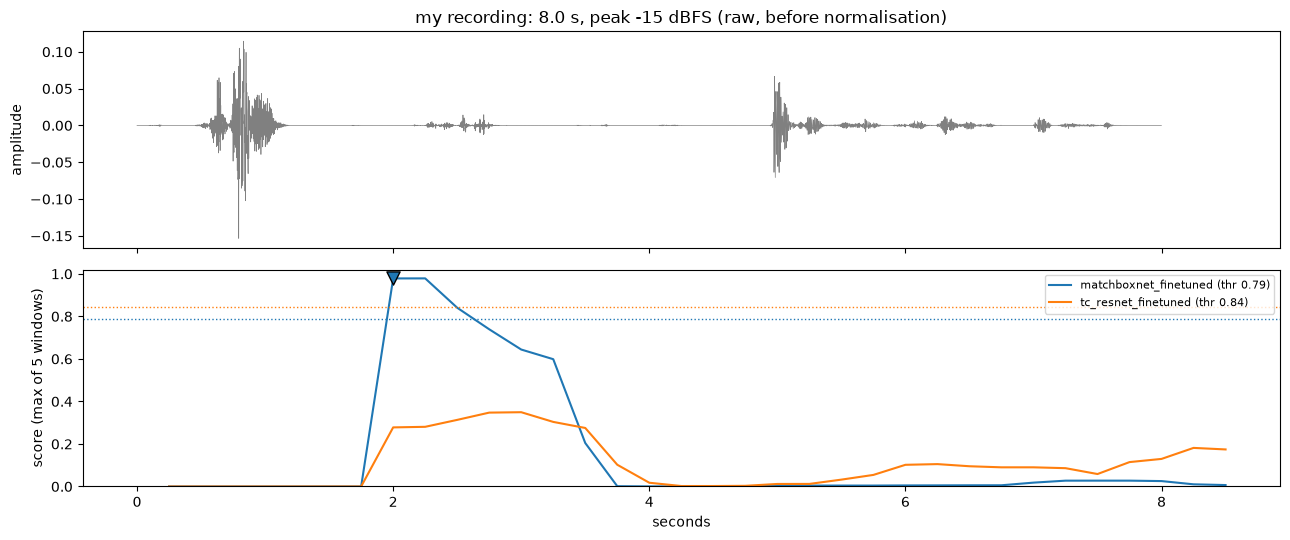

,fired,first_at_s,max_score,threshold
model,,,,
matchboxnet_finetuned,1,2.0,0.979,0.789
tc_resnet_finetuned,0,NaN,0.349,0.845


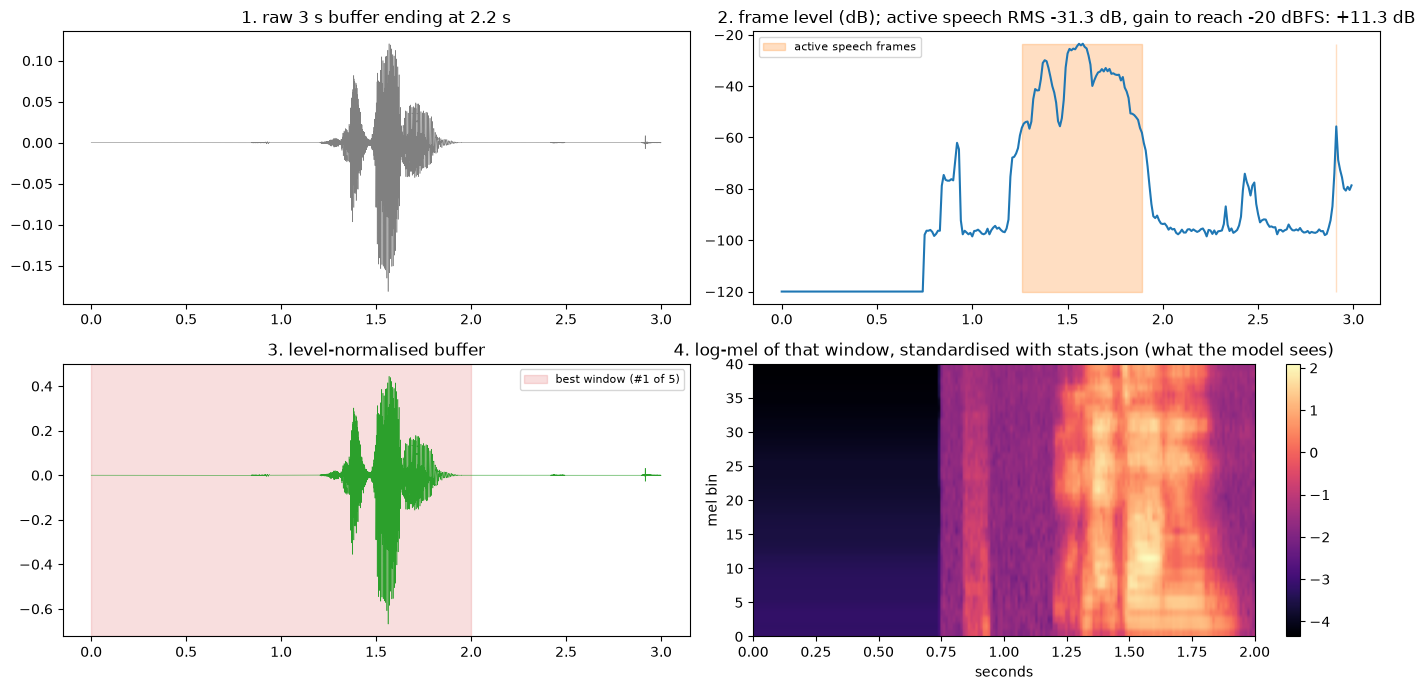

In [5]:
import sounddevice as sd

SECONDS = 8
INPUT_DEVICE = None          # None = system default microphone; or an index / name from sd.query_devices()

def record(seconds=8, device=INPUT_DEVICE):
    # records mono at 16 kHz straight from the microphone (no processing is applied by this code)
    print(f"RECORDING for {seconds} s: speak now ...")
    x = sd.rec(int(seconds * P.SR), samplerate=P.SR, channels=1, dtype="float32", device=device); sd.wait()
    print("done"); return x.reshape(-1)

# print(sd.query_devices())  # uncomment to list microphones and pick INPUT_DEVICE
my_audio = record(SECONDS); R, LR = analyse(my_audio, "my recording")

### Optional: test an audio file instead
If you want to try a recording you already have, set `TEST_WAV` to its path and run the cell.

Saving test2.wav to test2.wav
level check: {'peak_dBFS': -9.9, 'speech_rms_dB': -24.6, 'background_dB': -120.0, 'snr_dB': 95.4, 'gain_applied_dB': 4.6, 'clipped_pct': 0.0}
-> OK


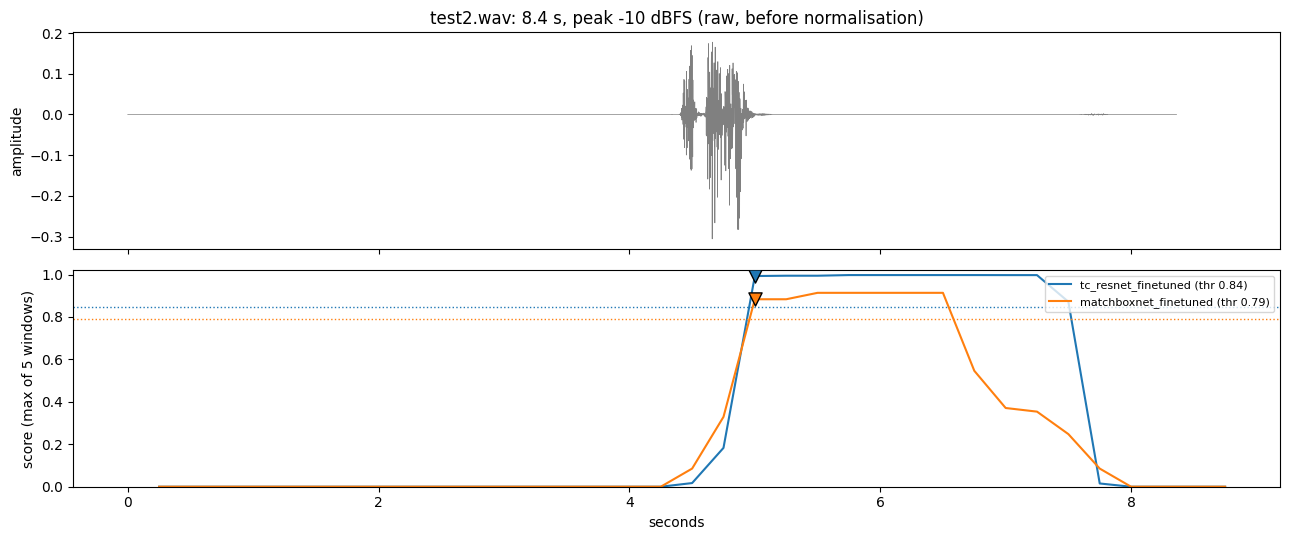

,fired,first_at_s,max_score,threshold
model,,,,
tc_resnet_finetuned,1,5.0,0.998,0.845
matchboxnet_finetuned,1,5.0,0.914,0.789


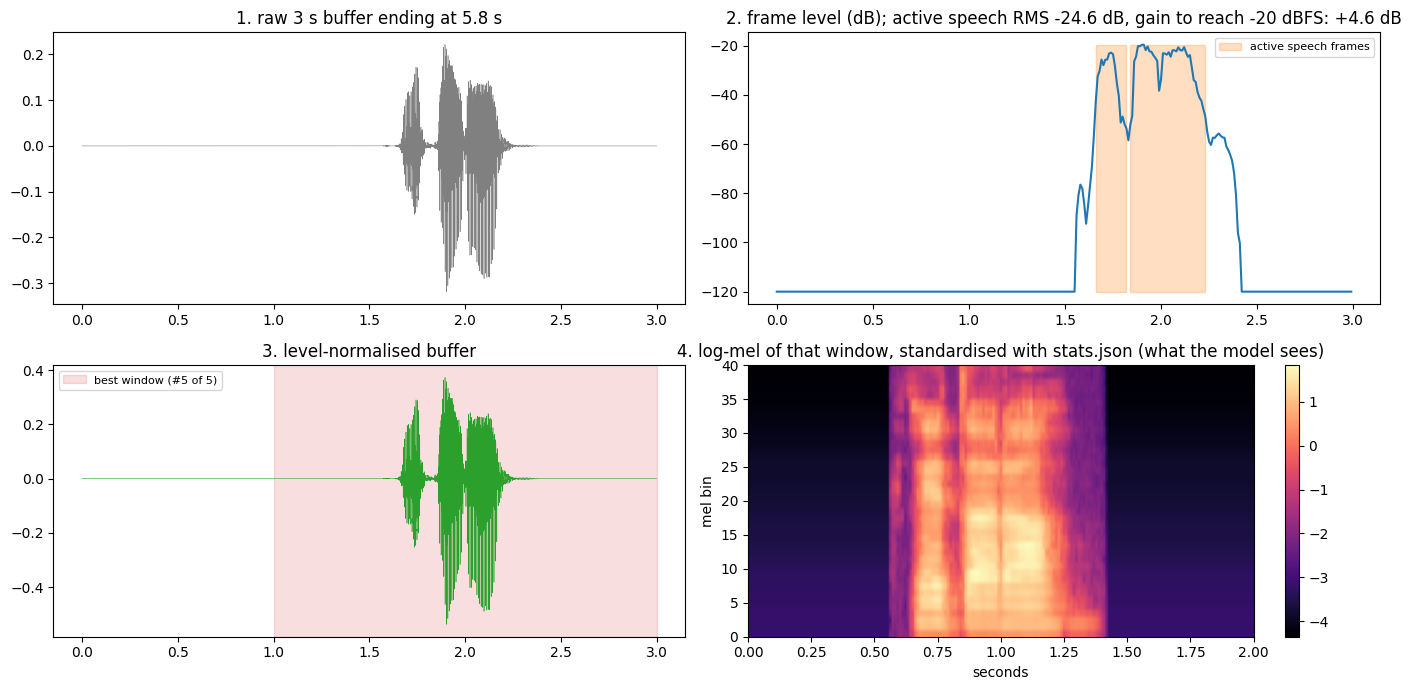

In [9]:
def load_audio(path):
    x, sr = sf.read(path, dtype="float32")
    if x.ndim > 1: x = x.mean(1)
    if sr != P.SR:
        from scipy.signal import resample_poly
        g = math.gcd(P.SR, sr); x = resample_poly(x, P.SR // g, sr // g).astype(np.float32)
    return x

TEST_WAV = None                                                      # e.g. "my_take.wav" (path to a local audio file readable by soundfile)
if TEST_WAV: R, LR = analyse(load_audio(TEST_WAV), Path(TEST_WAV).name)
else: print("set TEST_WAV to the path of a local audio file to analyse it")